In [3]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import xarray as xr
import netCDF4

In [97]:
#读取文件
ds = xr.open_dataset("200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc",engine="netcdf4") 
ds

<xarray.Dataset> Size: 54MB
Dimensions:                  (time: 210, bnds: 2, lat: 36, lon: 72, pressure: 10)
Coordinates:
  * time                     (time) datetime64[ns] 2kB 2003-01-16T12:00:00 .....
  * lat                      (lat) float64 288B -87.5 -82.5 -77.5 ... 82.5 87.5
  * lon                      (lon) float64 576B -177.5 -172.5 ... 172.5 177.5
Dimensions without coordinates: bnds, pressure
Data variables:
    time_bnds                (time, bnds) datetime64[ns] 3kB ...
    lat_bnds                 (lat, bnds) float64 576B ...
    lon_bnds                 (lon, bnds) float64 1kB ...
    pre                      (pressure) float64 80B ...
    pre_bnds                 (pressure, bnds) float64 160B ...
    land_fraction            (lat, lon) float64 21kB ...
    xch4                     (time, lat, lon) float32 2MB ...
    xch4_nobs                (time, lat, lon) float64 4MB ...
    xch4_stderr              (time, lat, lon) float32 2MB ...
    xch4_stddev              (time, lat, lon) float32 2MB ...
    column_averaging_kernel  (time, pressure, lat, lon) float32 22MB ...
    vmr_profile_ch4_apriori  (time, pressure, lat, lon) float32 22MB ...
Attributes: (12/28)
    activity_id:            obs4MIPs
    comment:                Since long time, climate modellers use ensemble a...
    contact:                Maximilian Reuter (maximilian.reuter@iup.physik.u...
    Conventions:            CF-1.7 ODS-2.1
    creation_date:          2021-02-05T09:48:47Z
    data_specs_version:     2.1.0
    ...                     ...
    source_version_number:  v4.3
    title:                  C3S XCH4 v4.3
    tracking_id:            892d184a-7b35-4bba-836a-94b9cfeb360e
    variable_id:            xch4
    variant_info:           Best Estimate
    variant_label:          BE

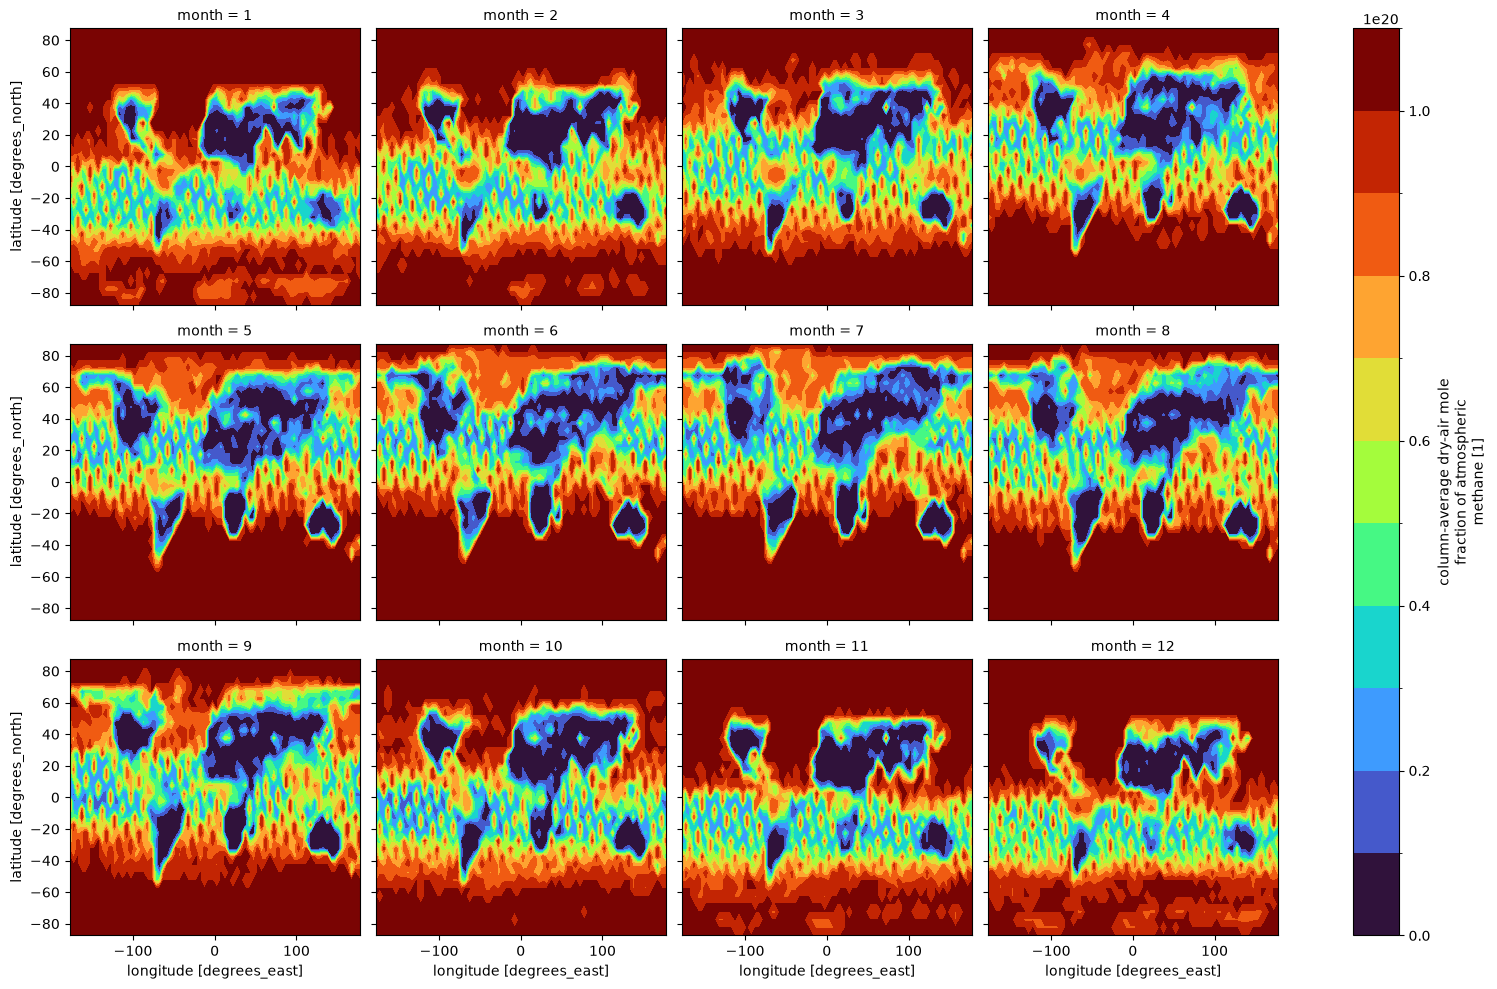

In [20]:
#按照月份分组，然后取平均
xch4_clim = ds.xch4.groupby('time.month').mean()
#按照不同月份进行画图，每四个换一行
xch4_clim.plot.contourf(col='month',col_wrap=4,levels=12,robust=True,cmap='turbo',figsize=(16, 10))
plt.show()

对甲烷数据进行清洗后按照经纬度求平均，然后绘制折线图。我们可以发现，在每一年中，甲烷的浓度都是呈现先上升后下降的趋势，在2003年到2020年间，全球甲烷浓度是呈现上升趋势的。

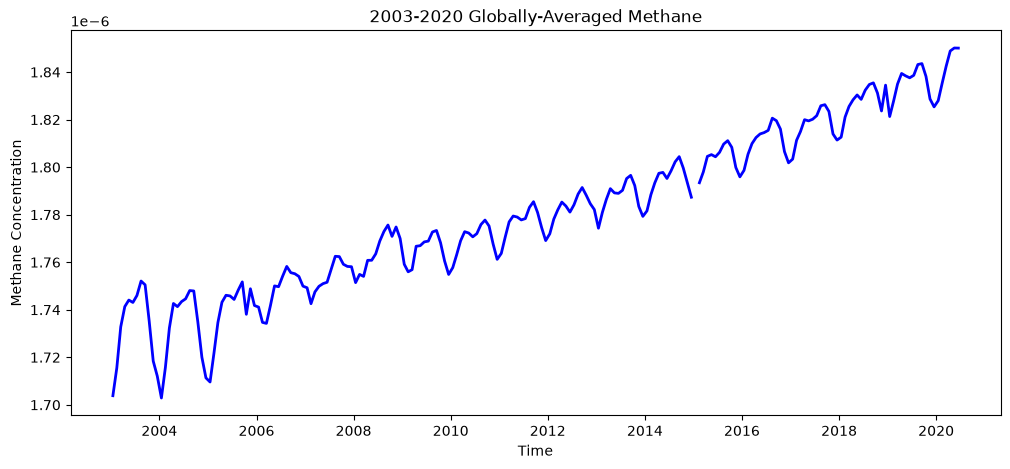

In [99]:
#对数据进行处理，大于等于1的设为缺失值
xch4_clean = ds.xch4.where(ds.xch4<1)
#按照经纬度求平均，这样得到每个时间点的全球平均甲烷数据
xch4_global = xch4_clean.mean(dim=['lat', 'lon'])
xch4_global.plot(figsize=(12, 5), color='blue', linewidth=2)
plt.title('2003-2020 Globally-Averaged Methane')
plt.ylabel('Methane Concentration')
plt.xlabel('Time')
plt.show()

去除月度季节周期后，南纬 15°、西经 150°附近的甲烷距平总体呈上升趋势。序列早期的有效观测多低于相应月份的多年平均，后期则多高于该平均。图中部分时段缺少有效观测，因此这一判断基于现有数据，仅供参考

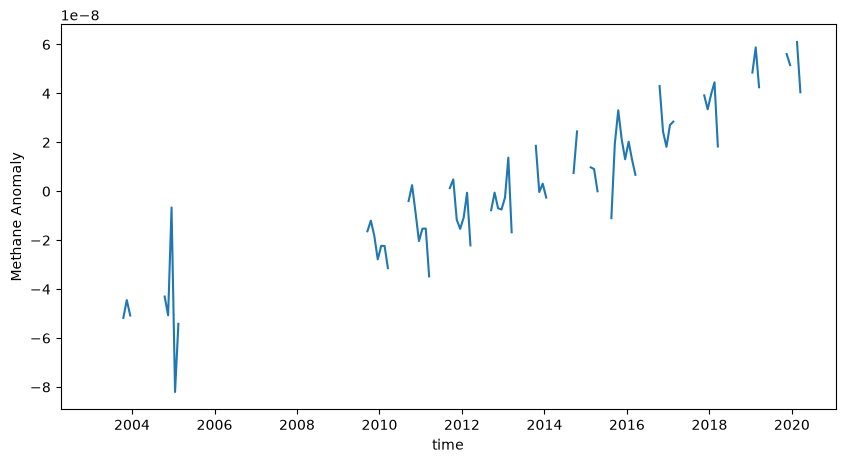

In [26]:
#筛选出南纬15°，西经150°的网格数据
xch4_date = ds.xch4.sel(lon=-150, lat=-15, method='nearest')
#进行数据清洗
xch4_clean = xch4_date.where(xch4_date < 1)
#求距平
xch4_clim = xch4_clean.groupby('time.month').mean()
xch4_anom = xch4_clean.groupby('time.month') - xch4_clim
xch4_anom.plot(figsize=(10, 5))
plt.ylabel('Methane Anomaly')
plt.show()

读取数据并选取研究区域。，取出 sst 变量，范围选中南纬 5° 到北纬 5°、西经 170° 到西经 120°。计算每个月的区域平均海温。 保留时间维度，得到 1960—2016 年每个月的区域平均海温。把不同年份的同一个月份分到一起，再沿时间求平均。计算海温距平并画图。 用每个实际月份的海温减去对应月份的参考值。并添加 0 参考线。高于 0 表示比多年同月平均偏暖，低于 0 表示偏冷。

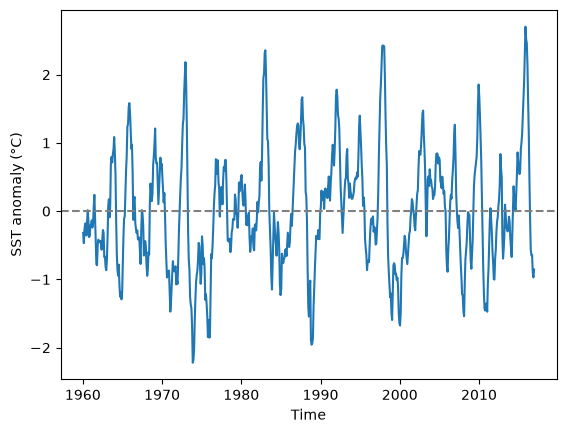

In [43]:
#读取文件
ds = xr.open_dataset('NOAA_NCDC_ERSST_v3b_SST(1).nc',engine="netcdf4")
#筛选出南北纬5°之间，西经120°~170°之间的区域
sst_region = ds.sst.sel(lat=slice(-5,5),lon=slice(190,240))
#按照经纬度求平均，这样得到每个时间点的区域平均SST数据
sst_mean = sst_region.mean(dim=['lat','lon'])
#计算月度平均SST
sst_clim = sst_mean.groupby('time.month').mean(dim='time')
#求距平，寻找异常值
sst_anom = sst_mean.groupby('time.month') - sst_clim
sst_anom.plot()
plt.ylabel('SST anomaly (°C)')
plt.xlabel('Time')
plt.axhline(0, color='grey', linestyle='--')
plt.show()

对月海温距平做 3 个月滑动平均。每次对连续 3 个月的距平求平均，并把结果记在中间的月份。用红蓝两色区分偏暖和偏冷。 以时间为横轴、3 个月平均海温距平（°C）为纵轴。用 fill_between() 把 0 线以上的区域填成红色，表示偏暖；把 0 线以下的区域填成蓝色，表示偏冷。添加参考线。 画出 0°C、+0.5°C 和 −0.5°C 三条水平线。0°C 表示与多年同月平均水平一致，±0.5°C 用来观察偏暖或偏冷的幅度。

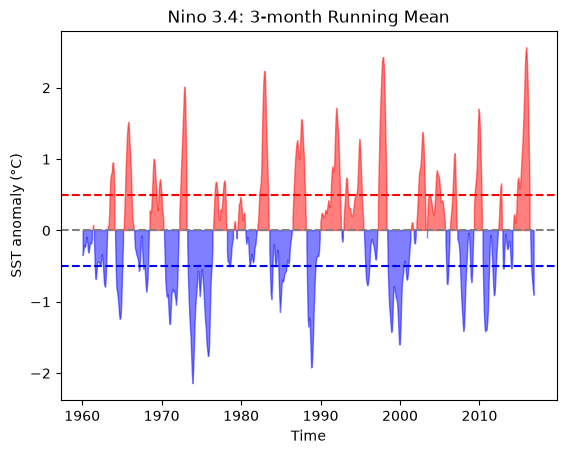

In [46]:
sst_nino = sst_anom.rolling(time=3, center=True).mean()
#正距平填红色
plt.fill_between(sst_nino.time.values, sst_nino.values, 0,where=sst_nino.values >= 0,color='red', alpha=0.5)
#负距平填蓝色
plt.fill_between(sst_nino.time.values, sst_nino.values, 0,where=sst_nino.values < 0,color='blue', alpha=0.5)
#添加0参考线
plt.axhline(0, color='grey', linestyle='--')
#根据厄尔尼诺的参考，距平正负0.5以内的是正常，所以加上±0.5°的参考线
plt.axhline(0.5, color='red', linestyle='--')
plt.axhline(-0.5, color='blue', linestyle='--')
plt.title('Nino 3.4: 3-month Running Mean')
plt.ylabel('SST anomaly (°C)')
plt.xlabel('Time')
plt.show()

读取惠州附近 2011—2020 年的逐日降水数据，把每个月的每日雨量相加，得到月累计降水量。把不同年份的同一个月放在一起求平均，得到 1—12 月各自的多年平均值。用每个月的实际雨量减去对应月份的多年平均值，得到降水距平。例如，2015 年 5 月的雨量减去这十年所有 5 月的平均雨量。以时间为横轴、降水距平（mm）为纵轴画折线图。高于 0 表示比多年同月平均偏湿，低于 0 表示偏干。

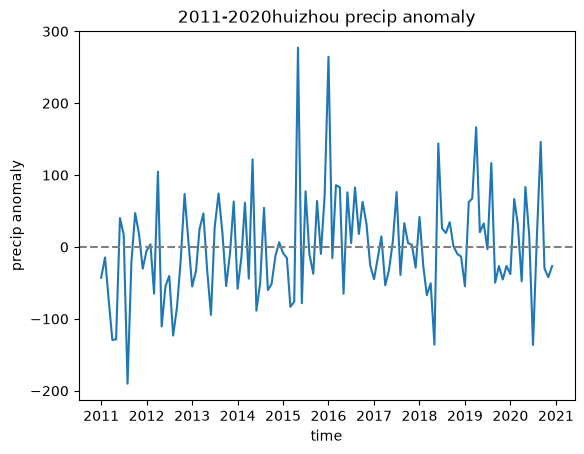

In [16]:
#读取数据，2011-2022惠州的每日降水量数据
data = xr.open_dataset('NASA_POWER_daily_precip_2011-2020.nc',engine = "netcdf4")
#将降水量的数据单独提取出来
date_month = data['PRECTOTCORR'].isel(lat=0, lon=0)
#按照月份求平均，然后标记是每月初
date_month_sum = date_month.resample(time='MS').sum()
#再求多年月平均降水
date_mean = date_month_sum.groupby('time.month').mean(dim='time')
#求距平
date_anom = date_month_sum.groupby('time.month') - date_mean
date_anom.plot()
plt.axhline(0,color='grey',linestyle='--')
plt.title('2011-2020huizhou precip anomaly')
plt.ylabel('precip anomaly')
plt.xlabel('time')
plt.show()

In [ ]:
绘制柱状图，这张柱状图显示：2011—2020 年惠州附近的降水有明显的季节差异，5—8 月通常较湿，11 月至次年 2 月通常较干。

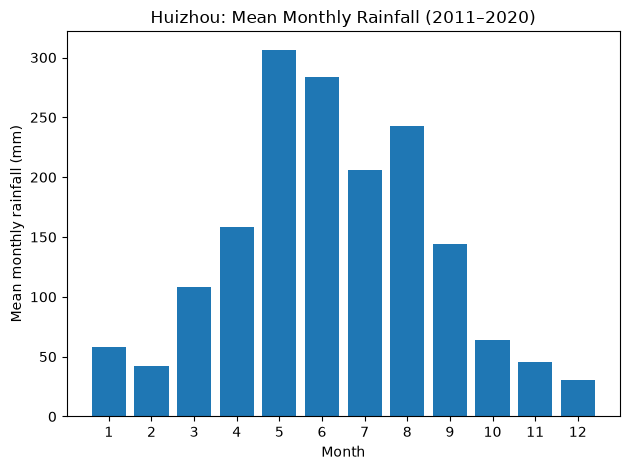

In [15]:
# 柱状图，横轴是1到12月，纵轴是每个月的多年平均累计雨量
plt.bar(date_mean['month'].values, date_mean.values)
plt.xticks(range(1, 13))
plt.xlabel('Month')
plt.ylabel('Mean monthly rainfall (mm)')
plt.title('Huizhou: Mean Monthly Rainfall (2011–2020)')
plt.tight_layout()
plt.show()


绘制每月总降水折线图。折线图显示，2011—2020 年惠州附近的月累计降水量有明显的季节变化：雨量较多的月份通常集中在春末和夏季，冬季则较少。

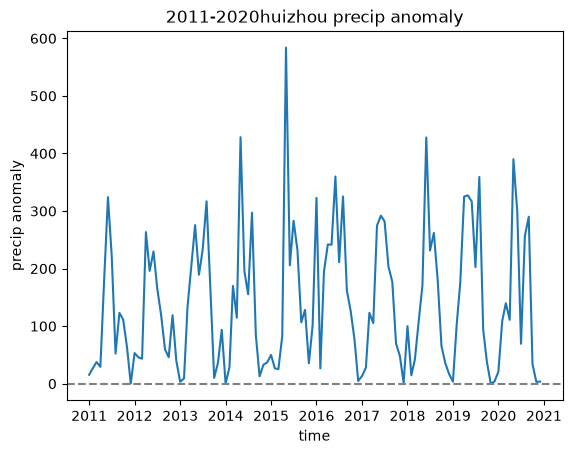

In [20]:
#数据清洗，保留
date_month_sum.plot()
plt.axhline(0,color='grey',linestyle='--')
plt.title('2011-2020huizhou precip anomaly')
plt.ylabel('precip anomaly')
plt.xlabel('time')
plt.show()

绘制月均箱型图。箱线图显示，2011—2020年惠州附近的月累计降水具有明显的季节差异。5—8月通常较湿，其中6月的降水中位数最高，约为295 mm；12月和1月的中位数较低。5月的箱体较高，表明不同年份的5月降水差异较大。1月虽然通常较干，但出现了约320 mm的离群高值，说明个别年份的冬季月份也可能明显偏湿。

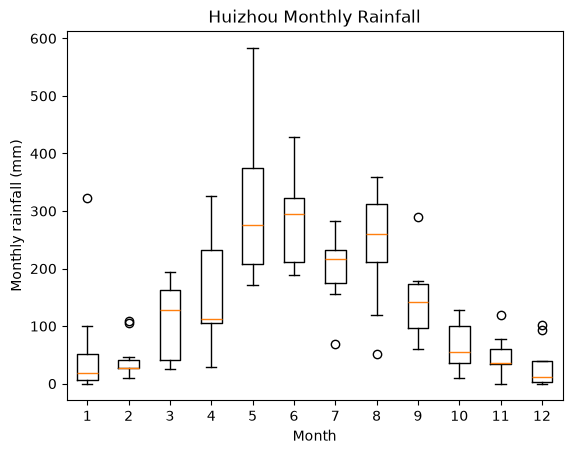

In [88]:
month_values = []
# 箱型图 第1组放10个年份的1月雨量，第2组放10个年份的2月雨量，以此类推
for month in range(1, 13):
    one_month = date_month.where(date_month.time.dt.month == month, drop=True)
    month_values.append(one_month.values)

plt.boxplot(month_values)
plt.xticks(range(1, 13))
plt.xlabel('Month')
plt.ylabel('Monthly rainfall (mm)')
plt.title('Huizhou Monthly Rainfall')
plt.show()

绘制年总降水量散点图，可以发现在2011年总降水量最少，2016年总降水量最多，年变化波动明显

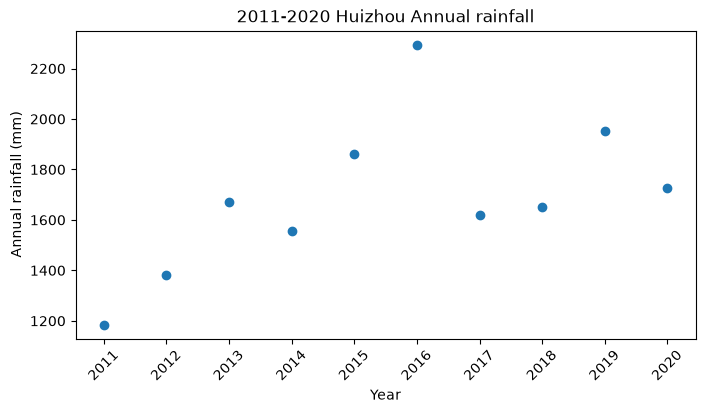

In [90]:
#把同一年每天的雨量相加，得到年累计雨量
date_year = date_region.resample(time='YS').sum()
#散点图：每个点代表一年的累计雨量
plt.figure(figsize=(8, 4))
plt.scatter(years, date_year.values)
plt.xticks(years, rotation=45)
plt.xlabel('Year')
plt.ylabel('Annual rainfall (mm)')
plt.title('2011-2020 Huizhou Annual rainfall')
plt.show()

绘制距平热图，热图展示了2011—2020年惠州附近逐月累计降水量相对于同月多年平均值的距平。2015年5月和2016年1月明显偏湿，2011年8月明显偏干。2018年5月偏干而6月偏湿，说明相邻月份的降水异常也可能方向相反。总体来看，降水距平在不同年份和月份之间波动明显。

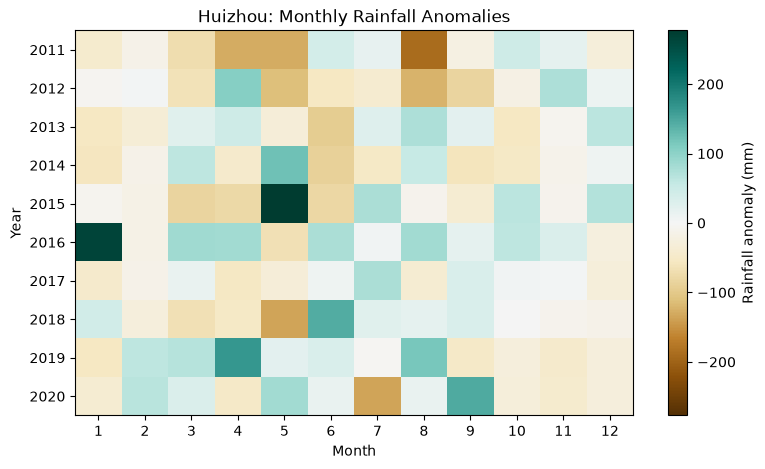

In [93]:
# 热图 把月距平转成表格，并加上年份和月份两列
table = date_anom.to_dataframe(name='anomaly')
table['year'] = table.index.year
table['month'] = table.index.month
#把表格排成：每行一个年份，每列一个月份
heat = table.pivot(index='year', columns='month', values='anomaly')
#让颜色范围在0的两侧对称，绿色偏湿，棕色偏干
max_anom = abs(heat.values).max()
plt.figure(figsize=(9, 5))
plt.imshow(heat.values, cmap='BrBG', aspect='auto', vmin=-max_anom, vmax=max_anom)
plt.xticks(range(12), heat.columns)
plt.yticks(range(10), heat.index)
plt.colorbar(label='Rainfall anomaly (mm)')
plt.xlabel('Month')
plt.ylabel('Year')
plt.title('Huizhou: Monthly Rainfall Anomalies')
plt.show()